
## Comprehensive Assignment on Numerical Solution to ODEs: Implementing the Leapfrog Method to Solve an IVP

### Overview
Every particle-in-cell (PIC) code advances its particles with the same core step: a leapfrog update of position and velocity under electric and magnetic fields. In this assignment, we write a leapfrog particle pusher from scratch and test it on the electron plasma oscillation problem, which sets the familiar PIC time-step limit. All quantities are in normalized units, so no physical constants are needed.

---

### 1. The Leapfrog Particle Pusher
A particle with charge-to-mass ratio $q/m$ obeys two coupled first-order ODEs:
$$\frac{dx}{dt} = v, \qquad \frac{dv}{dt} = \frac{q}{m}(E(x) + v \times B)$$

Leapfrog stores position at whole time levels $t_n = nh$ and velocity at half levels $t_{n+1/2} = \left(n + \frac{1}{2}\right)h$. Each step first updates the velocity using the force at the current position (**the kick**), then updates the position using the new velocity (**the drift**):
$$v_{n+1/2} = v_{n-1/2} + h \frac{q}{m} E_n$$
$$x_{n+1} = x_n + h v_{n+1/2}$$

The staggering makes the method second-order accurate with only one force evaluation per step. Because initial conditions give $v$ at $t = 0$, the velocity must first be moved back half a step to $v_{-1/2}$.

---

### 2. Electron Plasma Oscillation (Problem Formulation)
An electron displaced from equilibrium in a uniform, fixed ion background feels an electric field proportional to its displacement and oscillates at the plasma frequency $\omega_p$. In normalized units ($\omega_p = 1$), the governing equations and initial conditions are:

$$\frac{dx}{dt} = v, \qquad \frac{dv}{dt} = -\omega_p^2 x$$

* **Initial Conditions:** $x(0) = 0.5, \quad v(0) = 0$
* **Parameters & Domain:** $\omega_p = 1, \quad 0 \le t \le 20$
* **Exact Analytical Solution:**
  $$x(t) = 0.5 \cos(t), \qquad v(t) = -0.5 \sin(t)$$

---

### 3. Assignment Tasks
1. **Write a Python function:** Write a function `leapfrog(x, v, h)` that performs one leapfrog step and returns the new $x$ and $v$. Write it so that $x$ and $v$ can be arrays holding many particles, as in a PIC code.
2. **Initialize the half step:** Compute the staggered starting velocity from:
   $$v_{-1/2} = v_0 - \frac{h}{2} a(x_0), \qquad a(x) = -\omega_p^2 x$$
3. **Check implementation:** Integrate with $h = 0.1$ to $t = 20$. Plot $x$ at whole levels and $v$ at half levels against the exact solution, using the correct time for each. Plot the phase-space trajectory ($x$ against $v$).
4. **Plot convergence:** Repeat for $h = 0.2, 0.1, 0.05,$ and $0.025$. Tabulate the maximum error in $x$ and estimate the observed order $p = \log_2(e(h)/e(h/2))$. Then repeat with the unstaggered start $v_{-1/2} = v_0$. Remark on what happens to the order and explain why.
5. **Find out order of the method:** Eliminate $v$ to show that the scheme is equivalent to the central-difference formula:
   $$x_{n+1} - 2x_n + x_{n-1} = -\omega_p^2 h^2 x_n$$
6. **Derive stability limit:** Derive the stability condition $\omega_p h < 2$ from its characteristic roots, and confirm it by running with $\omega_p h = 1.9, 1.99, 2.01,$ and $2.1$. Explain why this is the plasma-frequency time-step condition every explicit PIC code must satisfy.


In [13]:
import numpy as np
import matplotlib.pyplot as plt

### Mathematical Formulation and Discretization Logic

In a standard central-difference discretization around time level $t_n$, we usually take a step forward to $n+1$ and a step backward to $n-1$ over a total span of $2h$:
$$\left.\frac{dv}{dt}\right|_n \approx \frac{v_{n+1} - v_{n-1}}{2h}$$

In the **staggered leapfrog method**, we apply the exact same central-difference concept, except instead of stepping to $n+1$ and $n-1$, we step half a grid spacing forward ($n+1/2$) and half a grid spacing backward ($n-1/2$) around $t_n$. This shrinks the total span from $2h$ down to $h$:
$$\left.\frac{dv}{dt}\right|_n \approx \frac{v_{n+1/2} - v_{n-1/2}}{h}$$

Similarly, for the position derivative $\frac{dx}{dt} = v$, we center the difference around the half-step $t_{n+1/2}$ by stepping $+h/2$ forward to $n+1$ and $-h/2$ backward to $n$:
$$\left.\frac{dx}{dt}\right|_{n+1/2} \approx \frac{x_{n+1} - x_n}{h} = v_{n+1/2}$$

---

### Connection to the Electron Plasma Oscillation Equations

From the general Lorentz force equation given in the problem statement:
$$\frac{d\mathbf{v}}{dt} = \frac{q}{m}(\mathbf{E}(\mathbf{x}) + \mathbf{v} \times \mathbf{B}) = \frac{q}{m}\mathbf{F}$$
Applying our half-step central difference yields the kick-drift equations:
$$\mathbf{v}_{n+1/2} = \mathbf{v}_{n-1/2} + h \frac{q}{m} \mathbf{F}_n, \qquad \mathbf{x}_{n+1} = \mathbf{x}_n + h \mathbf{v}_{n+1/2}$$

For the 1D electron plasma oscillation in normalized units ($\omega_p = 1$, with no explicit physical constants $q$ or $m$ needed), the governing velocity ODE is:
$$\frac{dv}{dt} = -\omega_p^2 x$$

Comparing the right-hand sides, the force-per-unit-mass term $\frac{q}{m} F_n$ is simply the acceleration $a(x_n) = -\omega_p^2 x_n$. Substituting this into our staggered central-difference formulas gives the final update rules for the code:

1. **Half-Step Velocity Initialization ($t = -h/2$):**
   Since initial conditions are given at $t = 0$, we first step velocity backward by $h/2$ to start the staggered grid:
   $$v_{-1/2} = v_0 - \frac{h}{2} a(x_0) = v_0 + \frac{h}{2} \omega_p^2 x_0$$

2. **Kick Step (Velocity update centered at $t_n$):**
   $$v_{n+1/2} = v_{n-1/2} - h \omega_p^2 x_n$$

3. **Drift Step (Position update centered at $t_{n+1/2}$):**
   $$x_{n+1} = x_n + h v_{n+1/2}$$

In [14]:
#defining the leapfrog function

def leapfrog(x,v,h,wp=1):
    v = v - h*wp**2*x
    x = x + h*v
    return x,v

In [15]:
h = 0.1
t_end = 20
wp = 1
n = int(t_end/h)
t_x = np.linspace(0,t_end,n+1)
t_v = t_x[:-1]+0.5*h
x_0 = 0.5
v_0 = 0.0

a_0 = -(wp**2) * x_0
v = v_0 - 0.5 * h * a_0
x = x_0

x_num = np.zeros(n + 1)
v_num = np.zeros(n)
x_num[0] = x

for i in range(n):
    x,v = leapfrog(x,v,h,wp)
    v_num[i] = v
    x_num[i+1] = x

x_exact = 0.5 * np.cos(t_x)
v_exact = -0.5 * np.sin(t_v)

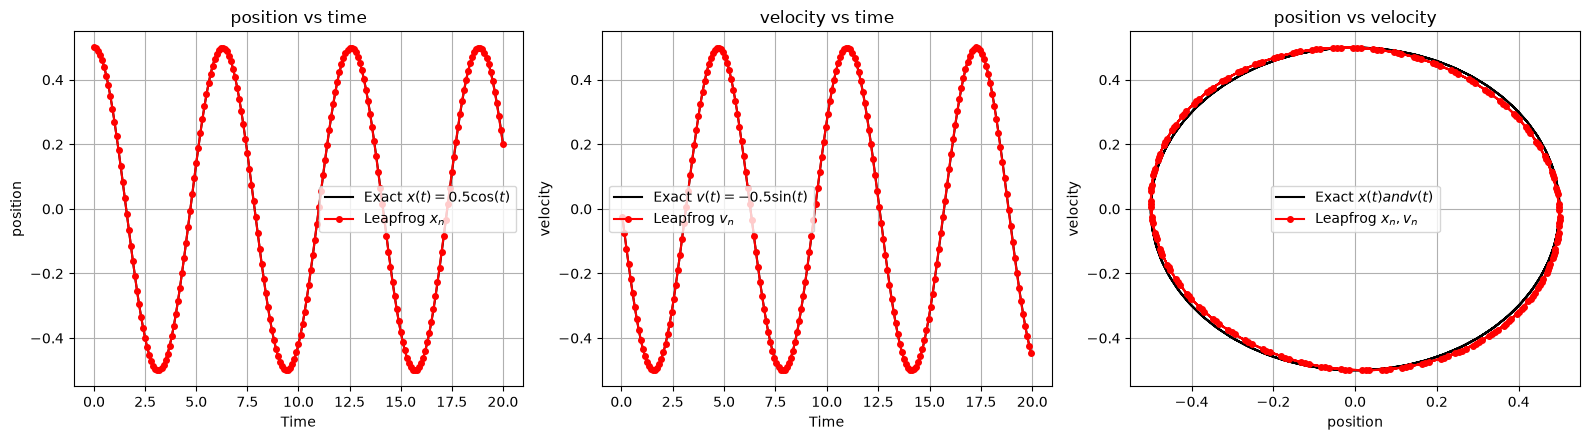

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(t_x, x_exact, 'k-', label='Exact $x(t) = 0.5\cos(t)$')
axes[0].plot(t_x,x_num,'ro-',markersize=4, label ='Leapfrog $x_n$')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('position')
axes[0].set_title('position vs time')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(t_v, v_exact, 'k-', label='Exact $v(t) = -0.5\sin(t)$')
axes[1].plot(t_v,v_num,'ro-',markersize=4, label ='Leapfrog $v_n$')
axes[1].set_xlabel('Time')
axes[1].set_ylabel('velocity')
axes[1].set_title('velocity vs time')
axes[1].legend()
axes[1].grid(True)

axes[2].plot(x_exact,-0.5 * np.sin(t_x), 'k-', label='Exact $x(t) and v(t)$')
axes[2].plot(x_num[:-1], v_num,'ro-',markersize=4,label ='Leapfrog $x_n, v_n$')
axes[2].set_xlabel('position')
axes[2].set_ylabel('velocity')
axes[2].set_title('position vs velocity')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
|